# Frequency & Wavelength — Intuition from a Rotating Dot

A **sine wave** is nothing more than the shadow of a dot spinning around a circle.  
As the dot travels around at a constant speed, its **vertical position** traces a perfect sine wave.

---

| Concept | Circle view | Wave view |
|---|---|---|
| **Frequency** *f* | How many full rotations per second (Hz) | How many complete cycles per second |
| **Period** *T = 1/f* | Time for one full rotation | Time between identical wave peaks |
| **Wavelength** *λ = v/f* | **One full circumference (2π rad) = one cycle → wave front advances exactly λ** | Distance one cycle occupies as it travels at speed *v* |
| **Angular freq.** *ω = 2πf* | Rotation speed in radians/second | Phase advance rate |

> **Wavelength on the circle:** the phasor lives in *phase space*, not physical space — there is no ruler on the circle.  
> But the link is direct: every time the dot completes **one full loop** (2π radians), the wave crest born at that instant has traveled forward by exactly **λ = v · T = v / f** metres.  
> The circle's circumference *encodes* one wavelength; wave speed *v* converts it to metres.

We'll build up the picture in three steps:
1. **Snapshots** — freeze the dot at 4 positions and see the sine values  
2. **Animation** — watch the dot spin and the wave unroll in real time  
3. **Interactive** — dial up the frequency and see how it squeezes the wavelength

In [17]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
from matplotlib.animation import FuncAnimation
from matplotlib.patches import Arc
from IPython.display import HTML
import ipywidgets as widgets
from ipywidgets import interact, FloatSlider
import warnings
warnings.filterwarnings('ignore')

%matplotlib inline
plt.rcParams.update({'figure.dpi': 110, 'font.size': 11})

## Step 1 — Snapshots: the dot's height *is* the sine value

Four equally-spaced moments in one rotation. The green dashed lines project the dot's **vertical (y) position** onto the wave on the right. That y-value is exactly `sin(θ)`.

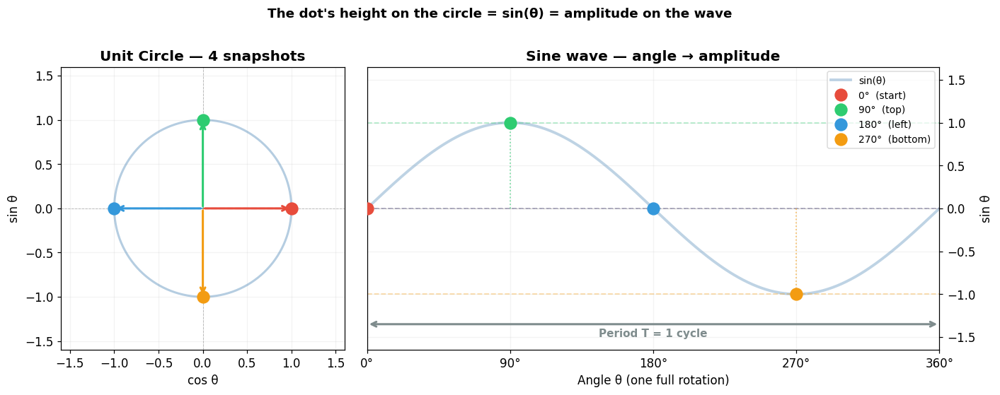

In [12]:
# ── Static Snapshot Diagram ──────────────────────────────────────────────────
angles_deg = [0, 90, 180, 270]
colors = ['#e74c3c', '#2ecc71', '#3498db', '#f39c12']
labels = ['0°  (start)', '90°  (top)', '180°  (left)', '270°  (bottom)']

fig, (ax_c, ax_w) = plt.subplots(1, 2, figsize=(13, 5),
                                  gridspec_kw={'width_ratios': [1, 2]})
plt.subplots_adjust(wspace=0.08)

# ── Circle ───────────────────────────────────────────────────────────────────
theta_ring = np.linspace(0, 2 * np.pi, 400)
ax_c.plot(np.cos(theta_ring), np.sin(theta_ring),
          color='steelblue', linewidth=2, alpha=0.4)
ax_c.axhline(0, color='gray', linewidth=0.6, linestyle='--', alpha=0.5)
ax_c.axvline(0, color='gray', linewidth=0.6, linestyle='--', alpha=0.5)

for deg, col, lbl in zip(angles_deg, colors, labels):
    rad = np.radians(deg)
    xd, yd = np.cos(rad), np.sin(rad)
    # Radius vector (phasor)
    ax_c.annotate('', xy=(xd, yd), xytext=(0, 0),
                  arrowprops=dict(arrowstyle='->', color=col, lw=2))
    # Dot on circle
    ax_c.plot(xd, yd, 'o', color=col, markersize=11, zorder=5)
    # Horizontal projection to y-axis (shows height)
    ax_c.plot([0, xd], [yd, yd], '--', color=col, linewidth=1.4, alpha=0.7)
    # Vertical drop to x-axis
    ax_c.plot([xd, xd], [0, yd], ':', color=col, linewidth=1.2, alpha=0.5)

ax_c.set_xlim(-1.6, 1.6)
ax_c.set_ylim(-1.6, 1.6)
ax_c.set_aspect('equal')
ax_c.set_title('Unit Circle — 4 snapshots', fontweight='bold')
ax_c.set_xlabel('cos θ');  ax_c.set_ylabel('sin θ')
ax_c.grid(True, alpha=0.15)

# ── Wave ─────────────────────────────────────────────────────────────────────
t_full = np.linspace(0, 2 * np.pi, 500)   # one full period = 2π
ax_w.plot(t_full, np.sin(t_full), color='steelblue', linewidth=2.5, alpha=0.35, label='sin(θ)')
ax_w.axhline(0, color='gray', linewidth=0.6, linestyle='--', alpha=0.5)

for deg, col, lbl in zip(angles_deg, colors, labels):
    rad = np.radians(deg)
    yd = np.sin(rad)
    ax_w.plot(rad, yd, 'o', color=col, markersize=11, zorder=5, label=lbl)
    # Horizontal line across wave panel at same height — shows projection
    ax_w.axhline(yd, color=col, linewidth=1.2, linestyle='--', alpha=0.35)
    # Vertical drop from dot to x-axis
    ax_w.plot([rad, rad], [0, yd], ':', color=col, linewidth=1.2, alpha=0.6)

# Annotate T (full period)
ax_w.annotate('', xy=(2 * np.pi, -1.35), xytext=(0, -1.35),
              arrowprops=dict(arrowstyle='<->', color='#7f8c8d', lw=2))
ax_w.text(np.pi, -1.5, 'Period T = 1 cycle', ha='center',
          color='#7f8c8d', fontsize=10, fontweight='bold')

ax_w.set_xlim(0, 2 * np.pi)
ax_w.set_ylim(-1.65, 1.65)
ax_w.set_xticks([0, np.pi/2, np.pi, 3*np.pi/2, 2*np.pi])
ax_w.set_xticklabels(['0°', '90°', '180°', '270°', '360°'])
ax_w.set_title('Sine wave — angle → amplitude', fontweight='bold')
ax_w.set_xlabel('Angle θ (one full rotation)')
ax_w.yaxis.tick_right();  ax_w.yaxis.set_label_position('right')
ax_w.set_ylabel('sin θ')
ax_w.legend(loc='upper right', fontsize=9, framealpha=0.7)
ax_w.grid(True, alpha=0.15)

plt.suptitle('The dot\'s height on the circle = sin(θ) = amplitude on the wave',
             fontsize=12, fontweight='bold', y=1.01)
plt.tight_layout()
plt.show()

## Step 2 — Animation: watch the wave unroll

The **red dot** spins on the circle (left). Its height is continuously plotted as time advances (right), unrolling the sine wave. The **green dashed cursor** marks the current moment.

> Run the cell to generate the animation. It renders as an embedded HTML video — no extra backends needed.

In [13]:
def make_phasor_animation(freq=1.0, wave_speed=2.0, n_frames=150, interval=40):
    """
    Animates a dot spinning on the unit circle (left) while the corresponding
    sine wave unrolls over time (right).

    freq       : frequency in Hz
    wave_speed : propagation speed in m/s — used only to label λ
    n_frames   : total animation frames (≈ 2.5 periods shown)
    interval   : ms between frames
    """
    omega = 2 * np.pi * freq          # rad/s
    T     = 1.0 / freq                # period (s)
    lam   = wave_speed / freq         # wavelength (m)

    total_time = 2.5 * T
    times  = np.linspace(0, total_time, n_frames)
    t_fine = np.linspace(0, total_time, 800)
    y_fine = np.sin(omega * t_fine)

    # ── Figure layout ────────────────────────────────────────────────────────
    fig, (ax_c, ax_w) = plt.subplots(
        1, 2, figsize=(13, 4.8),
        gridspec_kw={'width_ratios': [1, 2.3]})
    plt.subplots_adjust(wspace=0.07)

    # ── Circle panel ─────────────────────────────────────────────────────────
    ring = np.linspace(0, 2 * np.pi, 400)
    ax_c.plot(np.cos(ring), np.sin(ring), color='steelblue', lw=2, alpha=0.4)
    ax_c.axhline(0, color='gray', lw=0.6, ls='--', alpha=0.5)
    ax_c.axvline(0, color='gray', lw=0.6, ls='--', alpha=0.5)
    ax_c.set_xlim(-1.65, 1.65);  ax_c.set_ylim(-1.65, 1.65)
    ax_c.set_aspect('equal')
    ax_c.set_title(f'Rotating dot   f = {freq} Hz', fontweight='bold')
    ax_c.set_xlabel('cos θ');  ax_c.set_ylabel('sin θ')
    ax_c.grid(True, alpha=0.15)

    radius_ln, = ax_c.plot([], [], color='tomato', lw=2.5)
    dot_c,     = ax_c.plot([], [], 'o', color='tomato', ms=13, zorder=6)
    proj_h,    = ax_c.plot([], [], '--', color='mediumseagreen', lw=1.5, alpha=0.85)
    proj_v,    = ax_c.plot([], [], ':', color='#aaa', lw=1.2, alpha=0.7)
    angle_txt  = ax_c.text(-1.58, 1.42, '', fontsize=10, color='tomato', fontweight='bold')

    # Angle arc (drawn fresh each frame via a patch — simpler: just text)
    omega_txt = ax_c.text(0.05, -1.58,
                          f'ω = {omega:.2f} rad/s', fontsize=9, color='#555')

    # ── Wave panel ───────────────────────────────────────────────────────────
    ax_w.plot(t_fine, y_fine, color='steelblue', lw=2, alpha=0.2, label='full wave')
    ax_w.axhline(0, color='gray', lw=0.6, ls='--', alpha=0.5)
    ax_w.set_xlim(0, total_time)
    ax_w.set_ylim(-1.65, 1.65)
    ax_w.set_xlabel('Time  (s)', fontsize=11)
    ax_w.yaxis.tick_right();  ax_w.yaxis.set_label_position('right')
    ax_w.set_ylabel('Amplitude', fontsize=11)
    ax_w.grid(True, alpha=0.15)
    ax_w.set_title(
        f'Sine wave   T = {T:.2f} s    λ = {lam:.2f} m  (v = {wave_speed} m/s)',
        fontweight='bold')

    # Period arrow annotation (static)
    ax_w.annotate('', xy=(T, -1.38), xytext=(0, -1.38),
                  arrowprops=dict(arrowstyle='<->', color='darkorange', lw=2))
    ax_w.text(T / 2, -1.55, f'T = {T:.2f} s', ha='center',
              color='darkorange', fontsize=10, fontweight='bold')

    wave_drawn, = ax_w.plot([], [], color='tomato', lw=2.5, zorder=4)
    dot_w,      = ax_w.plot([], [], 'o', color='tomato', ms=11, zorder=6)
    cursor_ln,  = ax_w.plot([], [], '--', color='mediumseagreen', lw=1.5, alpha=0.9)
    time_txt    = ax_w.text(0.02 * total_time, 1.45, '', fontsize=10, color='#333')

    # ── Init & Update ────────────────────────────────────────────────────────
    def _init():
        for artist in (radius_ln, dot_c, proj_h, proj_v,
                       wave_drawn, dot_w, cursor_ln):
            artist.set_data([], [])
        angle_txt.set_text('')
        time_txt.set_text('')
        return (radius_ln, dot_c, proj_h, proj_v,
                wave_drawn, dot_w, cursor_ln, angle_txt, time_txt)

    def _update(frame):
        t     = times[frame]
        theta = omega * t
        xd, yd = np.cos(theta), np.sin(theta)

        # Circle elements
        radius_ln.set_data([0, xd], [0, yd])
        dot_c.set_data([xd], [yd])
        proj_h.set_data([0, xd], [yd, yd])      # height → y-axis
        proj_v.set_data([xd, xd], [0, yd])      # vertical drop

        angle_txt.set_text(f'θ = {np.degrees(theta) % 360:.0f}°')

        # Wave elements
        mask = t_fine <= t
        wave_drawn.set_data(t_fine[mask], y_fine[mask])
        dot_w.set_data([t], [yd])
        cursor_ln.set_data([t, t], [-1.65, 1.65])   # vertical time cursor
        time_txt.set_text(f't = {t:.2f} s')

        return (radius_ln, dot_c, proj_h, proj_v,
                wave_drawn, dot_w, cursor_ln, angle_txt, time_txt)

    anim = FuncAnimation(fig, _update, frames=n_frames,
                         init_func=_init, interval=interval, blit=True)
    plt.close(fig)
    return anim


# Generate and display (f=1 Hz, wave speed=2 m/s → λ=2 m)
anim = make_phasor_animation(freq=1.0, wave_speed=2.0, n_frames=180)
HTML(anim.to_jshtml())

## Step 3 — Interactive: change frequency, see wavelength shrink

Drag the **frequency** slider.  
- Higher frequency → dot spins faster → more squeezed cycles → **shorter wavelength**.  
- Lower frequency → slower dot → stretched cycles → **longer wavelength**.  
- Wave speed *v* stays fixed; only the dot's spin rate (and thus λ) changes.

In [14]:
WAVE_SPEED = 2.0   # m/s — fixed across all plots

def plot_freq_explorer(freq):
    """Static snapshot at a given frequency: circle phase-wheels + one full period on wave."""
    omega = 2 * np.pi * freq
    T     = 1.0 / freq
    lam   = WAVE_SPEED / freq

    # Time axis: always show exactly 2 wavelengths (2 periods)
    t_end  = 2 * T
    t_fine = np.linspace(0, t_end, 600)
    y_fine = np.sin(omega * t_fine)

    fig, (ax_c, ax_w) = plt.subplots(
        1, 2, figsize=(13, 4.6),
        gridspec_kw={'width_ratios': [1, 2.3]})
    plt.subplots_adjust(wspace=0.07)

    # ── Circle ───────────────────────────────────────────────────────────────
    ring = np.linspace(0, 2 * np.pi, 400)
    ax_c.plot(np.cos(ring), np.sin(ring), color='steelblue', lw=2, alpha=0.4)
    ax_c.axhline(0, color='gray', lw=0.6, ls='--', alpha=0.5)
    ax_c.axvline(0, color='gray', lw=0.6, ls='--', alpha=0.5)

    # Show dot at t = T/4 (top of circle) as the "snapshot moment"
    snap_angles = np.linspace(0, 2 * np.pi, int(8 * freq) + 1)[:-1]
    for i, ang in enumerate(snap_angles):
        xd, yd = np.cos(ang), np.sin(ang)
        alpha  = 0.25 + 0.75 * (i / max(len(snap_angles) - 1, 1))
        ax_c.plot(xd, yd, 'o', color='tomato', ms=9, alpha=alpha, zorder=5)

    # Highlight the last dot (current phase = 0)
    ax_c.annotate('', xy=(1, 0), xytext=(0, 0),
                  arrowprops=dict(arrowstyle='->', color='tomato', lw=2.5))
    ax_c.plot(1, 0, 'o', color='tomato', ms=13, zorder=6)
    ax_c.plot([1, 1], [0, 0], '--', color='mediumseagreen', lw=1.5, alpha=0.7)

    # Frequency annotation inside circle
    ax_c.text(0, 0, f'f = {freq:.1f} Hz\nω = {omega:.2f} rad/s\nT = {T:.3f} s',
              ha='center', va='center', fontsize=9.5, color='#2c3e50',
              bbox=dict(boxstyle='round,pad=0.35', facecolor='#ecf0f1', alpha=0.85))

    ax_c.set_xlim(-1.65, 1.65);  ax_c.set_ylim(-1.65, 1.65)
    ax_c.set_aspect('equal')
    ax_c.set_title('Phasor (unit circle)', fontweight='bold')
    ax_c.set_xlabel('cos θ');  ax_c.set_ylabel('sin θ')
    ax_c.grid(True, alpha=0.15)

    # ── Wave ─────────────────────────────────────────────────────────────────
    ax_w.plot(t_fine, y_fine, color='tomato', lw=2.5)
    ax_w.axhline(0, color='gray', lw=0.6, ls='--', alpha=0.5)

    # Shade exactly one period
    t_shade = np.linspace(0, T, 300)
    ax_w.fill_between(t_shade, np.sin(omega * t_shade), alpha=0.12, color='tomato')

    # Period arrow
    ax_w.annotate('', xy=(T, -1.38), xytext=(0, -1.38),
                  arrowprops=dict(arrowstyle='<->', color='darkorange', lw=2))
    ax_w.text(T / 2, -1.55, f'T = {T:.3f} s', ha='center',
              color='darkorange', fontsize=10, fontweight='bold')

    # Wavelength annotation (second period)
    ax_w.annotate('', xy=(2 * T, 1.38), xytext=(T, 1.38),
                  arrowprops=dict(arrowstyle='<->', color='steelblue', lw=2))
    ax_w.text(1.5 * T, 1.52, f'λ = v/f = {lam:.3f} m', ha='center',
              color='steelblue', fontsize=10, fontweight='bold')

    ax_w.set_xlim(0, t_end)
    ax_w.set_ylim(-1.65, 1.65)
    ax_w.set_xlabel('Time  (s)', fontsize=11)
    ax_w.yaxis.tick_right();  ax_w.yaxis.set_label_position('right')
    ax_w.set_ylabel('Amplitude', fontsize=11)
    ax_w.grid(True, alpha=0.15)
    ax_w.set_title(
        f'Sine wave — f = {freq:.1f} Hz,  T = {T:.3f} s,  '
        f'λ = {lam:.3f} m  (v = {WAVE_SPEED} m/s)', fontweight='bold')

    plt.suptitle(
        f'Key relation:  λ = v / f = {WAVE_SPEED} / {freq:.1f} = {lam:.3f} m',
        fontsize=12, fontweight='bold', color='#2c3e50', y=1.02)

    plt.tight_layout()
    plt.show()


interact(
    plot_freq_explorer,
    freq=FloatSlider(
        value=1.0, min=0.5, max=4.0, step=0.25,
        description='Frequency (Hz)',
        style={'description_width': 'initial'},
        layout=widgets.Layout(width='480px')
    )
);

interactive(children=(FloatSlider(value=1.0, description='Frequency (Hz)', layout=Layout(width='480px'), max=4…

## Summary — the big picture

```
dot spinning on a circle
        │
        ▼
 angular velocity ω = 2πf  (rad/s)
        │
        ├──► frequency  f  = ω / 2π        (Hz  = cycles/second)
        │
        ├──► period     T  = 1 / f          (seconds per cycle)
        │
        └──► wavelength λ  = v · T = v / f  (metres per cycle, at wave speed v)
```

**Rule of thumb:**  doubling the frequency → halves the wavelength (and period).  
That inverse relationship — **λ ∝ 1/f** — is the core of wave physics.

## Insight — Radius = Amplitude; same ω → same λ

Two circles with the **same angular frequency ω** but **different radii**:

| | Small circle (r = 0.5) | Large circle (r = 1.5) |
|---|---|---|
| **Amplitude** | 0.5 | 1.5 |
| **Frequency f** | same | same |
| **Period T** | same | same |
| **Wavelength λ** | same | same |
| **Linear dot speed** ω·r | smaller | **larger** |

The dot on the bigger circle covers more arc-length per second (`v_dot = ω·r`),
but that distance is in *phase space* — it does **not** change the wavelength.
**Wavelength is set only by ω and wave speed v, not by how big the circle is.**

What *does* change is the **amplitude** of the resulting wave — the crest height — which equals r.

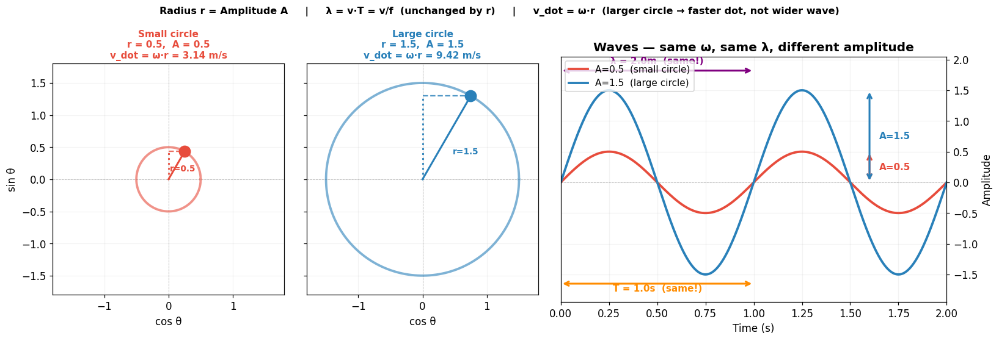

In [16]:
# Two concentric phasors: same ω, different radii → same λ, different amplitude

OMEGA  = 2 * np.pi * 1.0   # ω = 2π rad/s  (f = 1 Hz)
R_SMALL = 0.5
R_LARGE = 1.5
V_WAVE  = 2.0

t_wave = np.linspace(0, 2.0 / 1.0, 600)  # 2 full periods

fig, axes = plt.subplots(1, 3, figsize=(15, 5),
                          gridspec_kw={'width_ratios': [1.2, 1.2, 2]})
ax_s, ax_l, ax_w = axes
plt.subplots_adjust(wspace=0.08)

# ── Shared circle drawing helper ─────────────────────────────────────────────
def draw_phasor_circle(ax, r, color, label, snap_theta=np.pi/3):
    ring = np.linspace(0, 2*np.pi, 400)
    ax.plot(r*np.cos(ring), r*np.sin(ring), color=color, lw=2.5, alpha=0.6)
    # dot at snap_theta
    xd, yd = r*np.cos(snap_theta), r*np.sin(snap_theta)
    ax.plot([0, xd], [0, yd], color=color, lw=2)        # radius arm
    ax.plot(xd, yd, 'o', color=color, ms=12, zorder=6)  # dot
    # projection: dot height → y-axis  (= amplitude)
    ax.plot([0, xd], [yd, yd], '--', color=color, lw=1.5, alpha=0.8)
    ax.plot([0, 0],  [0, yd],  ':', color=color, lw=2,   alpha=0.9)
    # radius label
    ax.text(r*0.52*np.cos(snap_theta/2), r*0.52*np.sin(snap_theta/2),
            f'r={r}', color=color, fontsize=9, fontweight='bold', ha='center')
    # linear speed annotation
    v_dot = OMEGA * r
    ax.set_title(f'{label}\nr = {r},  A = {r}\nv_dot = ω·r = {v_dot:.2f} m/s',
                 fontsize=10, fontweight='bold', color=color)

# ── Small circle (left) ──────────────────────────────────────────────────────
lim_s = R_LARGE + 0.3
ax_s.axhline(0, color='gray', lw=0.6, ls='--', alpha=0.5)
ax_s.axvline(0, color='gray', lw=0.6, ls='--', alpha=0.5)
draw_phasor_circle(ax_s, R_SMALL, '#e74c3c', 'Small circle', snap_theta=np.pi/3)
ax_s.set_xlim(-lim_s, lim_s);  ax_s.set_ylim(-lim_s, lim_s)
ax_s.set_aspect('equal')
ax_s.set_xlabel('cos θ');  ax_s.set_ylabel('sin θ')
ax_s.grid(True, alpha=0.15)

# ── Large circle (middle) ────────────────────────────────────────────────────
ax_l.axhline(0, color='gray', lw=0.6, ls='--', alpha=0.5)
ax_l.axvline(0, color='gray', lw=0.6, ls='--', alpha=0.5)
draw_phasor_circle(ax_l, R_LARGE, '#2980b9', 'Large circle', snap_theta=np.pi/3)
ax_l.set_xlim(-lim_s, lim_s);  ax_l.set_ylim(-lim_s, lim_s)
ax_l.set_aspect('equal')
ax_l.set_xlabel('cos θ');  ax_l.set_ylabel('')
ax_l.yaxis.set_ticklabels([])
ax_l.grid(True, alpha=0.15)

# ── Wave panel (right) ───────────────────────────────────────────────────────
y_small = R_SMALL * np.sin(OMEGA * t_wave)
y_large = R_LARGE * np.sin(OMEGA * t_wave)

ax_w.plot(t_wave, y_small, color='#e74c3c', lw=2.5, label=f'A={R_SMALL}  (small circle)')
ax_w.plot(t_wave, y_large, color='#2980b9', lw=2.5, label=f'A={R_LARGE}  (large circle)')
ax_w.axhline(0, color='gray', lw=0.6, ls='--', alpha=0.5)

# Amplitude markers
T = 2*np.pi / OMEGA  # period = 1 s
ax_w.annotate('', xy=(1.6*T, R_SMALL), xytext=(1.6*T, 0),
              arrowprops=dict(arrowstyle='<->', color='#e74c3c', lw=2))
ax_w.text(1.65*T, R_SMALL/2, f'A={R_SMALL}', color='#e74c3c',
          va='center', fontsize=10, fontweight='bold')

ax_w.annotate('', xy=(1.6*T, R_LARGE), xytext=(1.6*T, 0),
              arrowprops=dict(arrowstyle='<->', color='#2980b9', lw=2))
ax_w.text(1.65*T, R_LARGE/2, f'A={R_LARGE}', color='#2980b9',
          va='center', fontsize=10, fontweight='bold')

# Period arrow (same for both)
ax_w.annotate('', xy=(T, -1.65), xytext=(0, -1.65),
              arrowprops=dict(arrowstyle='<->', color='darkorange', lw=2))
ax_w.text(T/2, -1.78, f'T = {T:.1f}s  (same!)', ha='center',
          color='darkorange', fontsize=10, fontweight='bold')

lam = V_WAVE / 1.0
ax_w.annotate('', xy=(T, 1.82), xytext=(0, 1.82),
              arrowprops=dict(arrowstyle='<->', color='purple', lw=2))
ax_w.text(T/2, 1.93, f'λ = {lam:.1f}m  (same!)', ha='center',
          color='purple', fontsize=10, fontweight='bold')

ax_w.set_xlim(0, 2*T);  ax_w.set_ylim(-1.95, 2.05)
ax_w.set_xlabel('Time (s)')
ax_w.yaxis.tick_right();  ax_w.yaxis.set_label_position('right')
ax_w.set_ylabel('Amplitude')
ax_w.grid(True, alpha=0.15)
ax_w.legend(loc='upper left', fontsize=10)
ax_w.set_title('Waves — same ω, same λ, different amplitude',
               fontweight='bold')

plt.suptitle(
    'Radius r = Amplitude A     |     λ = v·T = v/f  (unchanged by r)     |     v_dot = ω·r  (larger circle → faster dot, not wider wave)',
    fontsize=10.5, fontweight='bold', y=1.01)
plt.tight_layout()
plt.show()


## Phasor space vs Phase space

These two terms sound similar but come from different traditions. Our circle is *both* simultaneously.

### Phasor space (signal processing / EE)
A **phasor** is the complex number $Ae^{i\phi}$ representing a sinusoid.
The *phasor diagram* is drawn in the **complex plane** (Re/Im axes).
A phasor rotating at $\omega$ rad/s sweeps out a circle of radius $A$ (the amplitude).
The physical signal is the **Re projection** (the x-axis shadow).

$$x(t) = A\cos(\omega t) = \text{Re}\left[A e^{i\omega t}\right]$$

### Phase space (mechanics / dynamical systems)
For a system with position $x$ and velocity $\dot{x}$, **phase space** has axes $(x,\, \dot{x})$
— or equivalently $(x,\, p)$ where $p$ is momentum.  
A simple harmonic oscillator $\ddot{x} + \omega^2 x = 0$ has solution:

$$x(t) = A\cos(\omega t), \quad \dot{x}(t) = -A\omega\sin(\omega t)$$

Plotting $x$ vs $\dot{x}/\omega$ gives a **circle** — the energy is constant, oscillating between
kinetic ($\dot{x}^2$) and potential ($x^2$) with no loss.  
Add damping → **inward spiral** (energy lost). Drive it → **outward spiral** (energy added).

### Our circle is both
| | Phasor interpretation | Phase space interpretation |
|---|---|---|
| x-axis | Re part = $\cos(\omega t)$ | position $x(t)$ |
| y-axis | Im part = $\sin(\omega t)$ | velocity / $\omega = \dot{x}/\omega$ |
| Radius | Amplitude $A$ | $\sqrt{x^2 + (\dot{x}/\omega)^2}$ = constant |
| Circle = | One rotating frequency component | Conserved energy, perfect oscillator |

> The fact that both give the same circle is not a coincidence —
> a sinusoidal oscillator and a complex exponential are the same mathematical object.


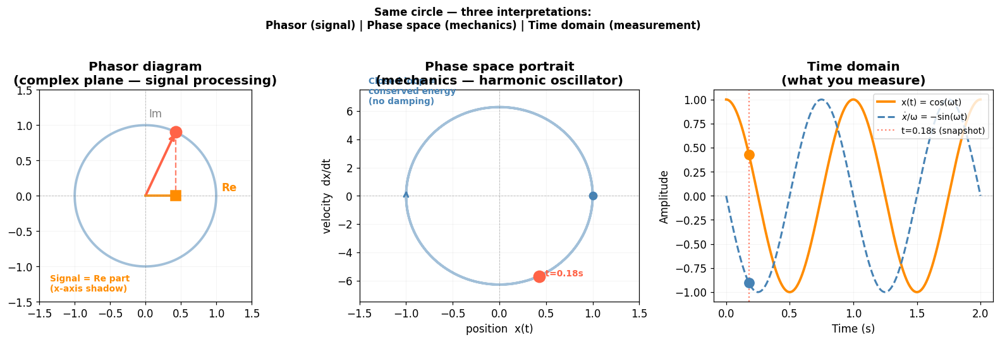

In [18]:
# Three views of the SAME circle:
#   Left  — Phasor diagram (complex plane, signal processing view)
#   Middle — Phase space portrait (x vs dx/dt, mechanics view)
#   Right  — Time-domain signal (what you actually measure)

omega = 2 * np.pi * 1.0   # 1 Hz
A     = 1.0
t_full = np.linspace(0, 2.0, 800)   # 2 periods
x_t   = A * np.cos(omega * t_full)
xdot_t = -A * omega * np.sin(omega * t_full)   # dx/dt

fig, (ax_p, ax_ps, ax_t) = plt.subplots(1, 3, figsize=(15, 4.8))
plt.subplots_adjust(wspace=0.28)

ring = np.linspace(0, 2*np.pi, 500)

# ── Phasor diagram (complex plane) ───────────────────────────────────────────
ax_p.plot(A*np.cos(ring), A*np.sin(ring), 'steelblue', lw=2.5, alpha=0.5)
# Rotating dot at t=0.18 s
t_snap = 0.18
xs = A*np.cos(omega*t_snap);  ys = A*np.sin(omega*t_snap)
ax_p.annotate('', xy=(xs, ys), xytext=(0, 0),
              arrowprops=dict(arrowstyle='->', color='tomato', lw=2.5))
ax_p.plot(xs, ys, 'o', color='tomato', ms=12, zorder=6)
# Re projection (physical signal)
ax_p.plot([xs, xs], [ys, 0], '--', color='tomato', lw=1.5, alpha=0.8)
ax_p.plot([0, xs],  [0, 0],  '-',  color='darkorange', lw=2.5, alpha=0.9)
ax_p.plot(xs, 0, 's', color='darkorange', ms=10, zorder=6,
          label=f'Re = cos(ωt) = {xs:.2f}')
ax_p.axhline(0, color='gray', lw=0.6, ls='--', alpha=0.5)
ax_p.axvline(0, color='gray', lw=0.6, ls='--', alpha=0.5)
ax_p.text(0.05, 1.08, 'Im', fontsize=11, va='bottom', color='gray')
ax_p.text(1.08, 0.03, 'Re', fontsize=11, va='bottom', color='darkorange', fontweight='bold')
ax_p.text(-1.35, -1.35,
          'Signal = Re part\n(x-axis shadow)',
          fontsize=9, color='darkorange', fontweight='bold')
ax_p.set_xlim(-1.5, 1.5);  ax_p.set_ylim(-1.5, 1.5)
ax_p.set_aspect('equal')
ax_p.set_title('Phasor diagram\n(complex plane — signal processing)', fontweight='bold')
ax_p.grid(True, alpha=0.12)

# ── Phase space portrait (x vs dx/dt) ────────────────────────────────────────
ax_ps.plot(x_t, xdot_t, color='steelblue', lw=2.5, alpha=0.5)
ax_ps.plot(x_t[0], xdot_t[0], 'o', color='steelblue', ms=8, label='t=0 (start)')
# Snapshot point
idx = int(t_snap / t_full[-1] * len(t_full))
ax_ps.plot(x_t[idx], xdot_t[idx], 'o', color='tomato', ms=12, zorder=6)
ax_ps.annotate(f'  t={t_snap}s', xy=(x_t[idx], xdot_t[idx]),
               fontsize=9, color='tomato', fontweight='bold')
# Arrow showing direction of travel
mid = len(t_full)//4
ax_ps.annotate('', xy=(x_t[mid+5], xdot_t[mid+5]), xytext=(x_t[mid], xdot_t[mid]),
               arrowprops=dict(arrowstyle='->', color='steelblue', lw=2))
ax_ps.axhline(0, color='gray', lw=0.6, ls='--', alpha=0.5)
ax_ps.axvline(0, color='gray', lw=0.6, ls='--', alpha=0.5)
ax_ps.set_xlim(-1.5, 1.5);  ax_ps.set_ylim(-7.5, 7.5)
ax_ps.set_xlabel('position  x(t)', fontsize=11)
ax_ps.set_ylabel('velocity  dx/dt', fontsize=11)
ax_ps.set_title('Phase space portrait\n(mechanics — harmonic oscillator)', fontweight='bold')
ax_ps.text(-1.4, 6.5,
           'Closed loop =\nconserved energy\n(no damping)',
           fontsize=9, color='steelblue', fontweight='bold')
ax_ps.grid(True, alpha=0.12)

# ── Time domain signal ────────────────────────────────────────────────────────
ax_t.plot(t_full, x_t, color='darkorange', lw=2.5, label='x(t) = cos(ωt)')
ax_t.plot(t_full, xdot_t/omega, '--', color='steelblue', lw=2,
          label=r'$\dot{x}$/ω = −sin(ωt)')
ax_t.axhline(0, color='gray', lw=0.6, ls='--', alpha=0.5)
ax_t.axvline(t_snap, color='tomato', lw=1.5, ls=':', alpha=0.8, label=f't={t_snap}s (snapshot)')
ax_t.plot(t_snap, A*np.cos(omega*t_snap), 'o', color='darkorange', ms=10, zorder=6)
ax_t.plot(t_snap, -np.sin(omega*t_snap), 'o', color='steelblue', ms=10, zorder=6)
ax_t.set_xlabel('Time (s)');  ax_t.set_ylabel('Amplitude')
ax_t.set_title('Time domain\n(what you measure)', fontweight='bold')
ax_t.legend(fontsize=9, loc='upper right')
ax_t.grid(True, alpha=0.12)

plt.suptitle(
    'Same circle — three interpretations:\n'
    'Phasor (signal) | Phase space (mechanics) | Time domain (measurement)',
    fontsize=11, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()
